In [1]:
# --.. ..- .-.. .-.. --- --.. ..- .-.. .-.. --- --.. ..- .-.. .-.. ---
# Z3ST: An open-source FEniCSx framework for thermo-mechanical analysis
# Author: Giovanni Zullo
# Version: 0.4.1 (2026)
# --.. ..- .-.. .-.. --- --.. ..- .-.. .-.. --- --.. ..- .-.. .-.. ---

# Interactive 3D fields

Reads the run named in `post.yaml` (`fields`) through `gui_fields.load_grid`. Stress and strain are in the local frame of the flats: nn through the wall, ss along the flat, zz along the axis. `sigma_vm` is the von Mises stress, frame-independent.

Needs the trame backend: `pip install "pyvista[jupyter]"`.

In [2]:
import numpy as np
import pyvista as pv
import ipywidgets as widgets

from gui_fields import D, H, NZ, XDMF, Z0, cells_as_points, layer_centre, load_grid, section
from z3st.utils.utils_extract_xdmf import list_steps_xdmf

pv.set_jupyter_backend("trame")
N_STEPS = len(list_steps_xdmf(XDMF, "Displacement"))


WARP_FRACTION = 0.2   # auto warp: peak |u| drawn as this fraction of H, enough to see the bow


def show(field="T (K)", step=-1, deformed=True, warp=0.0, cut=True, edges=False, view="iso"):
    """One field on the original or deformed shape; ``warp=0`` draws the peak |u| as
    ``WARP_FRACTION`` of H (never below true scale), ``cut`` keeps the lower half so the
    through-wall gradient shows on the cut face, ``view="side"`` looks along x at the
    y-z plane, where the duct bows."""
    grid = load_grid(step)
    if deformed:
        u_max = max(np.linalg.norm(grid.point_data["u"], axis=1).max(), 1e-30)
        warp = warp or max(1.0, WARP_FRACTION * H / u_max)
        mesh = grid.warp_by_vector("u", factor=warp)
    else:
        mesh = grid
    if cut:
        mesh = mesh.clip(normal="z", origin=(0, 0, H / 2))
    p = pv.Plotter()
    title = f"{field}, step {step}" + (f", deformed x{warp:.3g}" if deformed else "")
    p.add_text(title, font_size=10)
    if field is None:
        p.add_mesh(mesh, color="lightgray", show_edges=True, line_width=0.3)
    else:
        if field in mesh.cell_data:
            mesh = cells_as_points(mesh)
        p.add_mesh(mesh, scalars=field, preference="point", interpolate_before_map=False, cmap="turbo", show_edges=edges,
                   scalar_bar_args={"title": field, "fmt": "%.4g"})
    if deformed:
        p.add_mesh(grid.clip(normal="z", origin=(0, 0, H / 2)) if cut else grid,
                   style="wireframe", color="black", opacity=0.05)
    if view == "side":   # parallel projection: no perspective skew between the two ends
        p.view_yz()
        p.enable_parallel_projection()
    else:
        p.view_isometric()
    p.show()

## Mesh

In [3]:
show(None, deformed=False, cut=False)

Widget(value='<iframe src="http://localhost:35365/index.html?ui=P_0x71885524ce30_0&reconnect=auto" class="pyvi…

## Original shape, temperature

In [4]:
show("T (K)", deformed=False)

Widget(value='<iframe src="http://localhost:35365/index.html?ui=P_0x7188900fea80_1&reconnect=auto" class="pyvi…

## Deformed shape, displacement magnitude

In [5]:
show("u (um)")

Widget(value='<iframe src="http://localhost:35365/index.html?ui=P_0x718855202270_2&reconnect=auto" class="pyvi…

## Flexure

Whole length seen from the side (y-z plane): the bow of the duct, amplified.


In [6]:
show("u (um)", cut=False, view="side")

Widget(value='<iframe src="http://localhost:35365/index.html?ui=P_0x7188900fd640_3&reconnect=auto" class="pyvi…

## Stress

In [7]:
show("sigma_ss (MPa)")

/home/mat/z3st_macro/z3st/cases/sandbox/U_hex_shell/bowing/corner-corner/IAEA/VP1/gui_fields.py:120: PyVistaFutureWarning: The default value of `algorithm` for the filter
`UnstructuredGrid.extract_surface` will change in the future. It currently defaults to
`'dataset_surface'`, but will change to `None`. Explicitly set the `algorithm` keyword to
silence this warning.
  s = mesh.extract_surface().cast_to_unstructured_grid().separate_cells()


Widget(value='<iframe src="http://localhost:35365/index.html?ui=P_0x7188551bd100_4&reconnect=auto" class="pyvi…

## Von Mises stress

In [8]:
show("sigma_vm (MPa)")

Widget(value='<iframe src="http://localhost:35365/index.html?ui=P_0x718890262bd0_5&reconnect=auto" class="pyvi…

## Strain

In [9]:
show("eps_ss (-)")

Widget(value='<iframe src="http://localhost:35365/index.html?ui=P_0x71884426a630_6&reconnect=auto" class="pyvi…

## Explorer

Any field, step, warp, cut and view. Each change rebuilds the view.


In [10]:
g = load_grid()
fields = [k for k in g.point_data.keys() if k != "u"] + list(g.cell_data.keys())
widgets.interact(
    show,
    field=widgets.Dropdown(options=sorted(fields), value="sigma_ss (MPa)"),
    step=widgets.IntSlider(min=0, max=N_STEPS - 1, value=N_STEPS - 1),
    deformed=True,
    warp=widgets.FloatText(value=0.0, description="warp (0 = auto)"),
    cut=True,
    edges=False,
    view=widgets.Dropdown(options=["iso", "side"], value="iso"),
);

interactive(children=(Dropdown(description='field', index=5, options=('T (K)', 'eps_nn (-)', 'eps_ss (-)', 'ep…

## Section

The whole cross-section at a chosen height `z` (m), seen from above: all six flats and the full wall thickness. Uses `fields` from the Explorer cell above.

- The cut is placed at the mid-height of the element layer holding `z`, so it never falls on a face shared by two layers (the DG0 stress and strain would then be taken from either side).
- `deformed`: the section is warped by the in-plane displacement **relative to the section mean**, i.e. with the bow (rigid translation of the section, up to ~12 mm at the top) removed, so the distortion of the hexagon is visible. The undeformed outline is drawn in grey and the removed bow is printed in the title.
- Fields `u_rel (um)`: in-plane displacement relative to the section mean.
- Core: 1.5-2.5 m; above 2.5 m the section is in the uniform linear-T region.

In [11]:
def show_section(field="sigma_vm (MPa)", step=-1, z=2.5, deformed=False, warp=0.0, edges=True):
    """Whole hexagonal cross-section at the element layer holding ``z`` (m), seen from +z;
    ``warp=0`` draws the peak in-plane |u - mean| as 5 % of D, never below true scale."""
    grid = load_grid(step)
    sec, z_cut, u_mean = section(grid, z)
    title = f"{field}, step {step}, z = {z_cut:.4f} m (layer centre)"
    title += f"\nsection bow u_mean = ({u_mean[0] * 1e3:+.3f}, {u_mean[1] * 1e3:+.3f}) mm"
    outline = sec.extract_feature_edges(boundary_edges=True, feature_edges=False,
                                        manifold_edges=False, non_manifold_edges=False)
    if deformed:   # cut first, then warp: the section stays the one at z_cut
        u_rel = np.linalg.norm(sec.point_data["u_rel"][:, :2], axis=1).max()
        # below 1 nm the field is round-off (e.g. under the core, T = T_ref): true scale
        warp = warp or (max(1.0, 0.05 * D / u_rel) if u_rel > 1e-9 else 1.0)
        sec = sec.warp_by_vector("u_rel", factor=warp)
        title += f", distortion x{warp:.3g} (bow removed)"
    if field in sec.cell_data:
        sec = cells_as_points(sec)
    vals = sec.point_data[field]
    title += f"\n{field}: min {vals.min():.4g}, max {vals.max():.4g}"
    p = pv.Plotter()
    p.add_text(title, font_size=9)
    p.add_mesh(sec, scalars=field, preference="point", interpolate_before_map=False, cmap="turbo",
               show_edges=edges, line_width=0.3, scalar_bar_args={"title": field, "fmt": "%.4g"})
    if deformed:
        p.add_mesh(outline, color="gray", line_width=1.5, opacity=0.6)
    p.view_xy()
    p.enable_parallel_projection()
    p.show()


section_fields = sorted(set(fields) | {"u_rel (um)"})
widgets.interact(
    show_section,
    field=widgets.Dropdown(options=section_fields, value="sigma_vm (MPa)"),
    step=widgets.IntSlider(min=0, max=N_STEPS - 1, value=N_STEPS - 1),
    z=widgets.FloatSlider(min=Z0, max=Z0 + H, step=H / NZ, value=2.5 if Z0 <= 2.5 <= Z0 + H else Z0 + H / 2,
                          readout_format=".3f", description="z (m)", continuous_update=False),
    deformed=False,
    warp=widgets.FloatText(value=0.0, description="warp (0 = auto)"),
    edges=True,
);

interactive(children=(Dropdown(description='field', index=6, options=('T (K)', 'eps_nn (-)', 'eps_ss (-)', 'ep…

## Benchmark IAEA N1 (S1)

z3st against the published IAEA results (benchmark N1, example 1, corner to corner): S1 Fig. 2 (thermal bow, digitized) and Table 1; Table I (reference case: Y, Z, mid-wall dimensions across corners OY and across flats OX); Table II (sensitivity: zero thickness, non adiabatic wrapper, the latter with another T field). Same run as above (`post.yaml`). Points beyond the tolerances (`tol_mm` **and** `tol_rel`) are listed in the table. Z and the dimensions depend on the stress-free temperature: z3st (T_ref = 400 C) is rebased to the T_ref of each source (S1 20 C, Table I / II 0 C). The figure is also saved in `U_hex_shell/results/IAEA_VP1_vs_benchmark.png` by `python vp1_benchmark.py`.

In [12]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import vp1_benchmark as vb

prof = vb.z3st_profiles(XDMF)


def show_benchmark(tol_mm=0.1, tol_rel=0.05, only_flagged=False):
    rows = vb.compare(prof, tol_mm, tol_rel)
    fig = vb.figure(prof, rows, tol_mm, tol_rel)
    plt.show()
    df = pd.DataFrame(rows)[["source", "quantity", "station", "z_mm", "z3st_mm", "benchmark_mm", "diff_mm", "rel", "flagged", "note"]]
    df["rel"] = 100 * df["rel"]
    df = df.rename(columns={"rel": "diff_%"})
    display((df[df.flagged] if only_flagged else df).style.format(precision=3).apply(
        lambda r: ["background-color: #ffe0b2" if r.flagged else "" for _ in r], axis=1))


widgets.interact(
    show_benchmark,
    tol_mm=widgets.FloatText(value=0.1, description="tol (mm)"),
    tol_rel=widgets.FloatText(value=0.05, description="tol (rel)"),
    only_flagged=False,
);

interactive(children=(FloatText(value=0.1, description='tol (mm)'), FloatText(value=0.05, description='tol (re…

### Bow along z, benchmark Fig. 2 layout

Deflection DT (mm) on x, height above the support (COTE, mm) on y, as in Fig. 2 of the benchmark; z3st and the closed form overlaid.

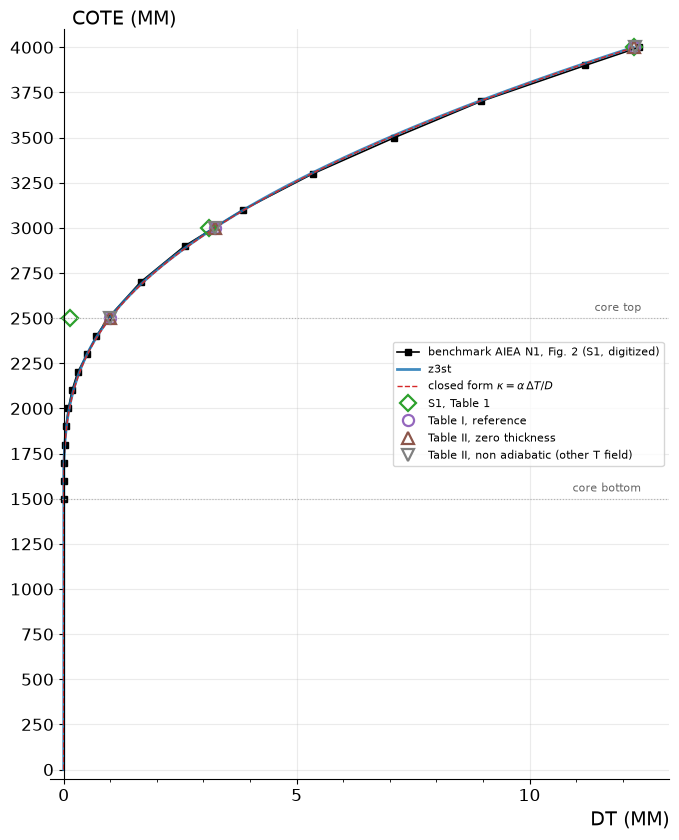

In [13]:
vb.figure_fig2(prof)
plt.show()

### Full comparison with Table I / II

Every tabulated value against z3st; highlighted rows exceed both tolerances. Dimensions at mid-wall, measured at z = `vb.Z_BELOW` / `vb.Z_ABOVE`.

/home/mat/z3st_macro/z3st/cases/sandbox/U_hex_shell/hex_post.py:489: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=(0, 0, 1, top))


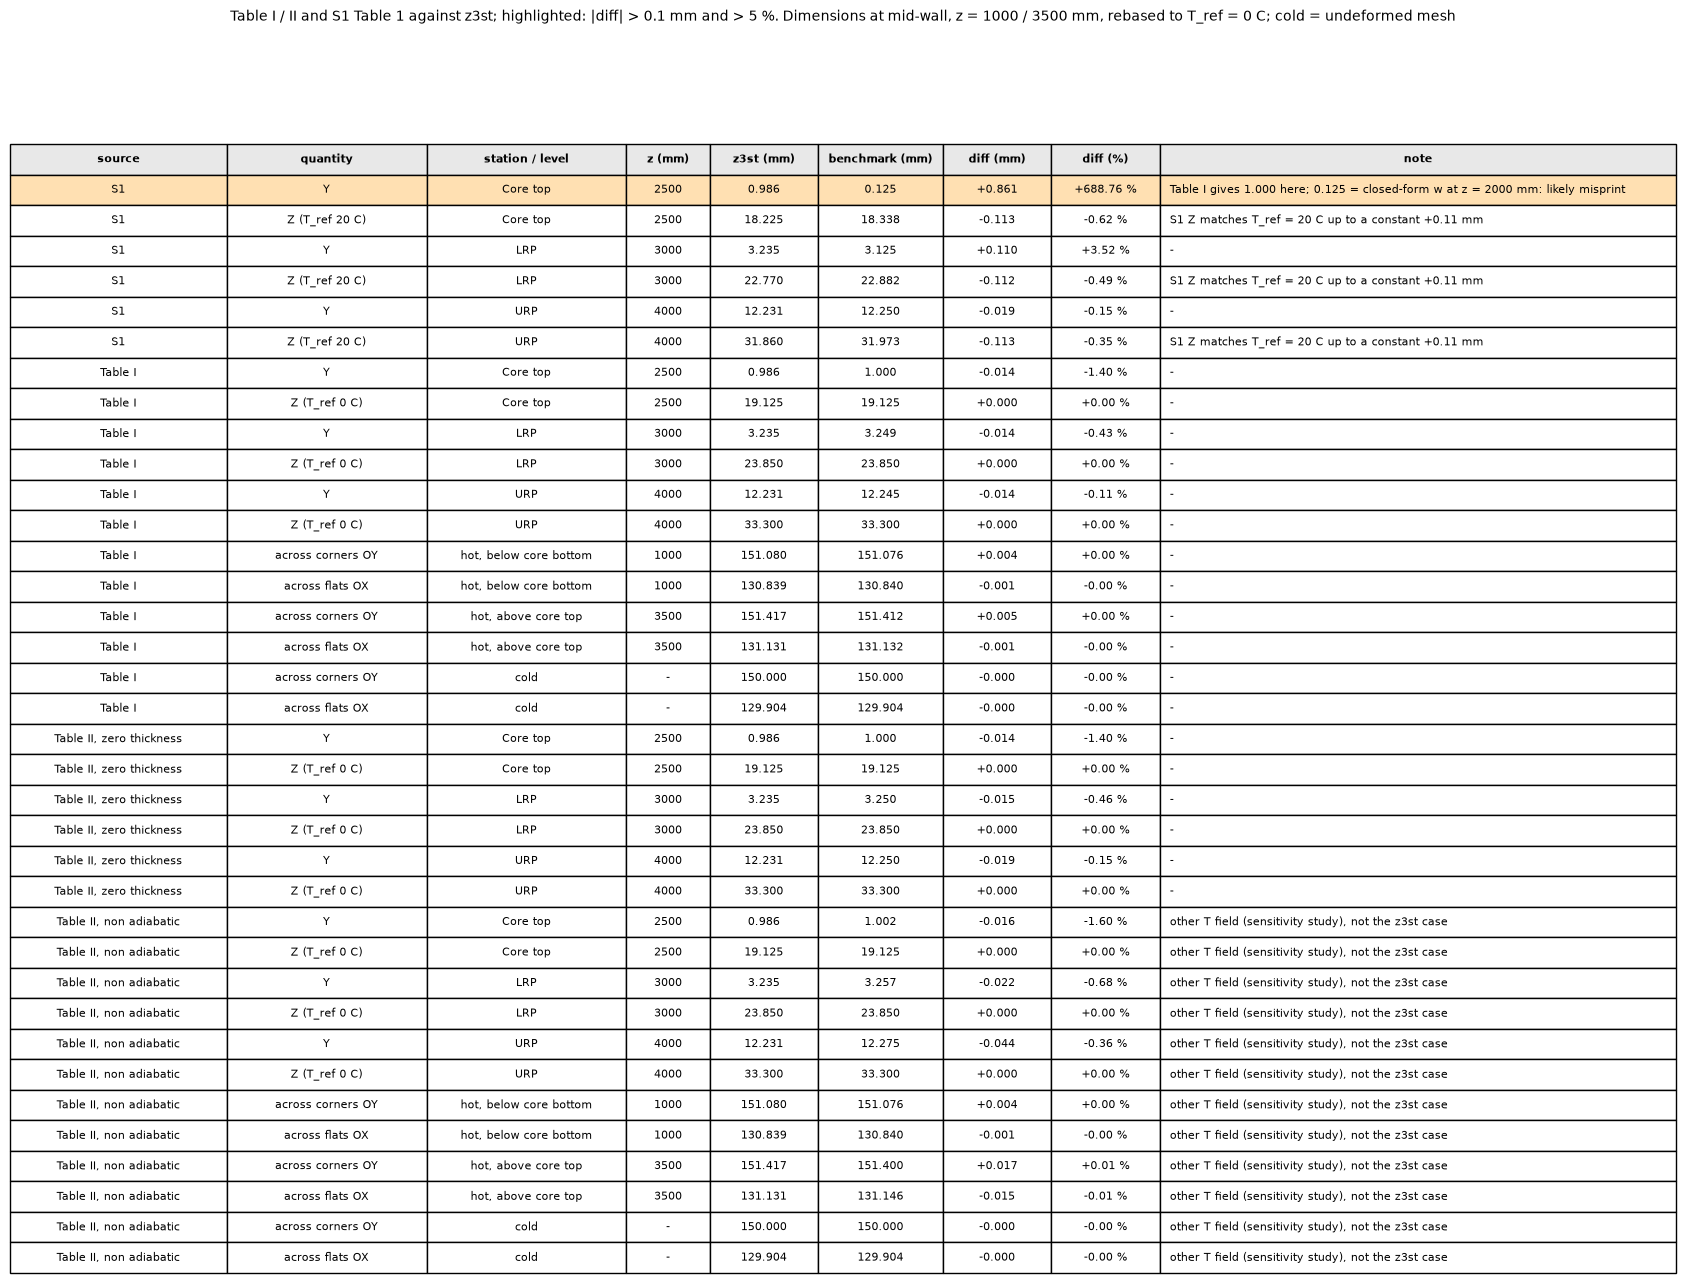

In [14]:
vb.figure_tables(vb.compare(prof, 0.1, 0.05), 0.1, 0.05)
plt.show()

## Hot and cold corner along z

u_y (mid-wall corner, with the section mean and the closed-form bow), stress (σ_zz, hoop σ_ss, von Mises) and total strain (ε_zz, ε_ss, with the free thermal strain α(T − T_ref)) of the two corners of extreme temperature. Stress and strain are the DG0 values of the two cells next to the corner, averaged. Away from the clamp and from the core ends T is linear in (x, y), the solution is stress-free and ε = α(T − T_ref).

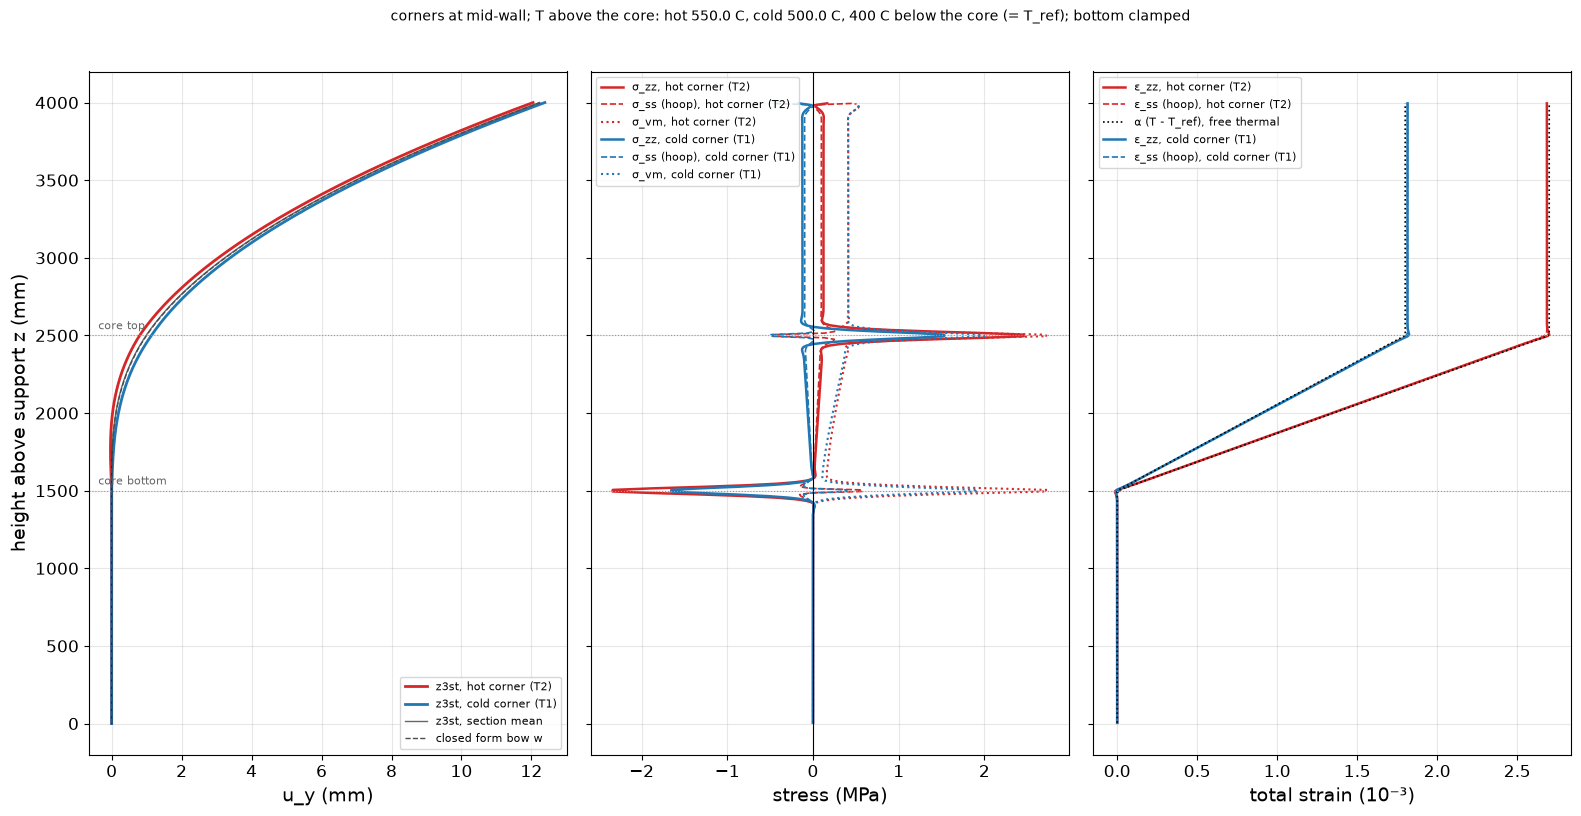

In [15]:
import vp1_corners as vc

vc.figure_corners(vc.corner_profiles(XDMF))
plt.show()